# Occlusion Accuracy by Image Category — Base Models

Per-subcategory accuracy for each model on the **occlusion** test (base eval, combined judge scoring: correct if either judge says so).
Categories from `data/Image categories (3).xlsx`, filtered to IDs in `annotations.json`.

**Direct** subcategories: Shadow · Specular (mirror/glass + other reflection + phone) · Water/Diffuse  
**Inferential** subcategories: Household · Machinery/Technology · Sports/Activity · Culture/Symbol · Nature

In [1]:
# Run from the repo root so the root-relative data paths below resolve
import os
from pathlib import Path
os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sec3_occludebench").is_dir()))

In [2]:
import json
import os
import openpyxl
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
from collections import defaultdict

import matplotlib as mpl
mpl.rcParams.update({
    'font.family':       'Arial',
    'font.size':         26,
    'axes.titlesize':    26,
    'axes.labelsize':    26,
    'xtick.labelsize':   26,
    'ytick.labelsize':   26,
    'legend.fontsize':   26,
    'axes.titleweight':  'normal',
    'axes.grid':         False,
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'figure.dpi':        150,
})

RESULTS_DIR      = 'data/eval_results'
ANNOTATIONS_PATH = 'data/combined_output/annotations.json'
EXCEL_PATH       = 'data/Image categories (3).xlsx'

MODEL_STEMS = [
    'gpt-5.4',
    'claude-opus-4-6',
    'gemini-3.1-pro-preview',
    'Qwen3-VL-8B-Instruct',
    'Llama-4-Maverick-17B-128E-Instruct-FP8-9940db5c',
]
DISPLAY_NAMES = {
    'gpt-5.4':                                               'GPT-5.4',
    'claude-opus-4-6':                                       'Claude Opus 4.6',
    'gemini-3.1-pro-preview':                                'Gemini 3.1 Pro',
    'Qwen3-VL-8B-Instruct':                                  'Qwen 3 VL 8B',
    'Llama-4-Maverick-17B-128E-Instruct-FP8-9940db5c':       'Llama 4 Maverick',
}
JUDGE_MODELS = ['gpt-5.4', 'claude-opus-4-6']

FIG_DIR = 'data/figures'
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name + '.pdf'), bbox_inches='tight', format='pdf')


In [3]:
# ── Load annotations ────────────────────────────────────────────────────────
with open(ANNOTATIONS_PATH) as f:
    annotations = json.load(f)
ann_set = set(item['id'] for item in annotations)

# ── Load & normalise category map from Excel ─────────────────────────────────
def normalize_id(x):
    if isinstance(x, float) and x == int(x):
        return str(int(x))
    return str(x)

SPECULAR_RAW = {'mirror/glass', 'other reflection', 'phone'}

wb = openpyxl.load_workbook(EXCEL_PATH)
ws = wb.active

id_to_cat  = {}   # img_id -> merged subcategory label
id_to_kind = {}   # img_id -> 'direct' | 'inferential'

for row in ws.iter_rows(values_only=True):
    if row[0] is None or row[0] == 'image id':
        continue
    img_id = normalize_id(row[0])
    if img_id not in ann_set:
        continue
    kind, subcat = row[1], row[2]
    # merge
    if subcat in SPECULAR_RAW:
        subcat = 'specular'
    elif subcat == 'water':
        subcat = 'water/diffuse'
    elif subcat == 'culture' or subcat == 'symbol':
        subcat = 'culture/symbol'
    id_to_cat[img_id]  = subcat
    id_to_kind[img_id] = kind

print(f'Categorised {len(id_to_cat)} images')
print('Direct categories:',      sorted({v for k,v in id_to_cat.items() if id_to_kind[k]=='direct'}))
print('Inferential categories:',  sorted({v for k,v in id_to_cat.items() if id_to_kind[k]=='inferential'}))

Categorised 378 images
Direct categories: ['shadow', 'specular', 'water/diffuse']
Inferential categories: ['culture/symbol', 'household', 'machinery/technology', 'nature', 'sports/activity']


In [4]:
# ── Compute per-category accuracy for one judged file ───────────────────────
def compute_cat_accuracy(judged_data, verdict_key, id_to_cat, id_to_kind, judge_models):
    sums   = defaultdict(float)
    counts = defaultdict(int)
    for item in judged_data:
        vdict = item.get(verdict_key, {})
        if not isinstance(vdict, dict):
            continue
        scores = [vdict[jm] for jm in judge_models if jm in vdict and vdict[jm] is not None]
        if not scores:
            continue
        score  = float(any(scores))
        img_id = str(item['id'])
        cat    = id_to_cat.get(img_id)
        if cat is None:
            continue
        sums[cat]   += score
        counts[cat] += 1
    return {cat: (sums[cat] / counts[cat] * 100, counts[cat])
            for cat in counts}

# ── Load all base judged results ──────────────────────────────────────────────
judged_cache = {}
for stem in MODEL_STEMS:
    path = os.path.join(RESULTS_DIR, f'{stem}_judged_results.json')
    with open(path) as f:
        judged_cache[stem] = json.load(f)

# ── Build per-model accuracy DataFrames ──────────────────────────────────────
DIRECT_CATS      = ['shadow', 'specular', 'water/diffuse']
INFERENTIAL_CATS = ['household', 'machinery/technology', 'sports/activity', 'culture/symbol', 'nature']
ALL_CATS         = DIRECT_CATS + INFERENTIAL_CATS

cat_acc = {}   # stem -> {cat: (acc, n)}
for stem in MODEL_STEMS:
    cat_acc[stem] = compute_cat_accuracy(
        judged_cache[stem], 'occluded_correct', id_to_cat, id_to_kind, JUDGE_MODELS
    )
    print(DISPLAY_NAMES[stem])
    for cat in ALL_CATS:
        acc, n = cat_acc[stem].get(cat, (None, 0))
        print(f'  {cat:<25} {acc:.1f}%  (n={n})' if acc is not None else f'  {cat:<25} N/A')
    print()

GPT-5.4
  shadow                    46.8%  (n=47)
  specular                  25.5%  (n=94)
  water/diffuse             50.0%  (n=56)
  household                 68.2%  (n=44)
  machinery/technology      62.2%  (n=45)
  sports/activity           61.3%  (n=31)
  culture/symbol            54.1%  (n=37)
  nature                    66.7%  (n=24)

Claude Opus 4.6
  shadow                    53.2%  (n=47)
  specular                  45.7%  (n=94)
  water/diffuse             60.7%  (n=56)
  household                 68.2%  (n=44)
  machinery/technology      75.6%  (n=45)
  sports/activity           90.3%  (n=31)
  culture/symbol            78.4%  (n=37)
  nature                    62.5%  (n=24)

Gemini 3.1 Pro
  shadow                    78.7%  (n=47)
  specular                  66.0%  (n=94)
  water/diffuse             75.0%  (n=56)
  household                 84.1%  (n=44)
  machinery/technology      88.9%  (n=45)
  sports/activity           93.5%  (n=31)
  culture/symbol            89.2%  

In [5]:
cat_labels_display = {
    'shadow':               'Shadow',
    'specular':             'Specular',
    'water/diffuse':        'Diffuse',
    'household':            'Household',
    'machinery/technology': 'Technology',
    'sports/activity':      'Activity',
    'culture/symbol':       'Culture',
    'nature':               'Nature',
}

rows = {}
for stem in MODEL_STEMS:
    row = {}
    for cat in ALL_CATS:
        acc, n = cat_acc[stem].get(cat, (None, 0))
        row[cat_labels_display[cat]] = f'{acc:.1f}%' if acc is not None else 'N/A'
    rows[DISPLAY_NAMES[stem]] = row

tbl = pd.DataFrame(rows).T
tbl = tbl[[cat_labels_display[c] for c in ALL_CATS]]
display(tbl)

,Shadow,Specular,Diffuse,Household,Technology,Activity,Culture,Nature
GPT-5.4,46.8%,25.5%,50.0%,68.2%,62.2%,61.3%,54.1%,66.7%
Claude Opus 4.6,53.2%,45.7%,60.7%,68.2%,75.6%,90.3%,78.4%,62.5%
Gemini 3.1 Pro,78.7%,66.0%,75.0%,84.1%,88.9%,93.5%,89.2%,83.3%
Qwen 3 VL 8B,29.8%,13.8%,25.5%,50.0%,46.7%,48.4%,40.5%,45.8%
Llama 4 Maverick,31.9%,24.5%,43.6%,47.7%,48.9%,38.7%,27.0%,45.8%


## Statistical Testing

For each model and category group (Direct / Inferential):
- **Chi-square omnibus test** across all categories in that group
- **Pairwise Fisher's exact tests** (Bonferroni-corrected) between every pair of categories

Outcomes are binarised: correct if either judge says so.

In [6]:
from scipy.stats import chi2_contingency, fisher_exact
from itertools import combinations

def collect_binary_outcomes(judged_data, verdict_key, id_to_cat, judge_models):
    """Returns {cat: [list of 0/1 outcomes]} correct if either judge says so."""
    outcomes = defaultdict(list)
    for item in judged_data:
        vdict = item.get(verdict_key, {})
        if not isinstance(vdict, dict):
            continue
        scores = [vdict[jm] for jm in judge_models if jm in vdict and vdict[jm] is not None]
        if not scores:
            continue
        binary = int(any(scores))
        cat    = id_to_cat.get(str(item['id']))
        if cat is not None:
            outcomes[cat].append(binary)
    return outcomes


def chi2_across_cats(outcomes, cats):
    """Chi-square test of independence across multiple categories."""
    table = np.array([[sum(outcomes[c]), len(outcomes[c]) - sum(outcomes[c])]
                      for c in cats if c in outcomes])
    if table.shape[0] < 2:
        return None, None
    chi2, p, dof, _ = chi2_contingency(table)
    return chi2, p


def pairwise_fisher(outcomes, cats, alpha=0.05):
    """
    All pairwise Fisher's exact tests, Bonferroni-corrected.
    Returns dict {(cat_a, cat_b): {'p_raw': .., 'p_adj': .., 'sig': bool}}.
    """
    pairs = list(combinations([c for c in cats if c in outcomes], 2))
    n_comparisons = len(pairs)
    results = {}
    for ca, cb in pairs:
        a = outcomes[ca]; b = outcomes[cb]
        contingency = [[sum(a), len(a) - sum(a)],
                       [sum(b), len(b) - sum(b)]]
        _, p = fisher_exact(contingency)
        p_adj = min(p * n_comparisons, 1.0)
        results[(ca, cb)] = {'p_raw': p, 'p_adj': p_adj, 'sig': p_adj < alpha}
    return results


def stars(p):
    if p < 0.001: return '***'
    if p < 0.01:  return '**'
    if p < 0.05:  return '*'
    return 'ns'


# ── Collect outcomes and run tests for all models ────────────────────────────
binary_outcomes = {}   # stem -> {cat: [outcomes]}
omnibus         = {}   # stem -> {'direct': (chi2,p), 'inferential': (chi2,p)}
pairwise        = {}   # stem -> {'direct': {...}, 'inferential': {...}}

for stem in MODEL_STEMS:
    bo = collect_binary_outcomes(judged_cache[stem], 'occluded_correct', id_to_cat, JUDGE_MODELS)
    binary_outcomes[stem] = bo
    omnibus[stem] = {
        'direct':      chi2_across_cats(bo, DIRECT_CATS),
        'inferential': chi2_across_cats(bo, INFERENTIAL_CATS),
    }
    pairwise[stem] = {
        'direct':      pairwise_fisher(bo, DIRECT_CATS),
        'inferential': pairwise_fisher(bo, INFERENTIAL_CATS),
    }

print('Omnibus chi-square results (p-values):')
print(f"{'Model':<25} {'Direct p':>12} {'Inferential p':>15}")
print('-' * 55)
for stem in MODEL_STEMS:
    _, dp = omnibus[stem]['direct']
    _, ip = omnibus[stem]['inferential']
    print(f"{DISPLAY_NAMES[stem]:<25} {dp:>12.4f} {ip:>15.4f}")

Omnibus chi-square results (p-values):
Model                         Direct p   Inferential p
-------------------------------------------------------
GPT-5.4                         0.0037          0.7488
Claude Opus 4.6                 0.2020          0.1242
Gemini 3.1 Pro                  0.2275          0.7190
Qwen 3 VL 8B                    0.0557          0.9393
Llama 4 Maverick                0.0524          0.2715


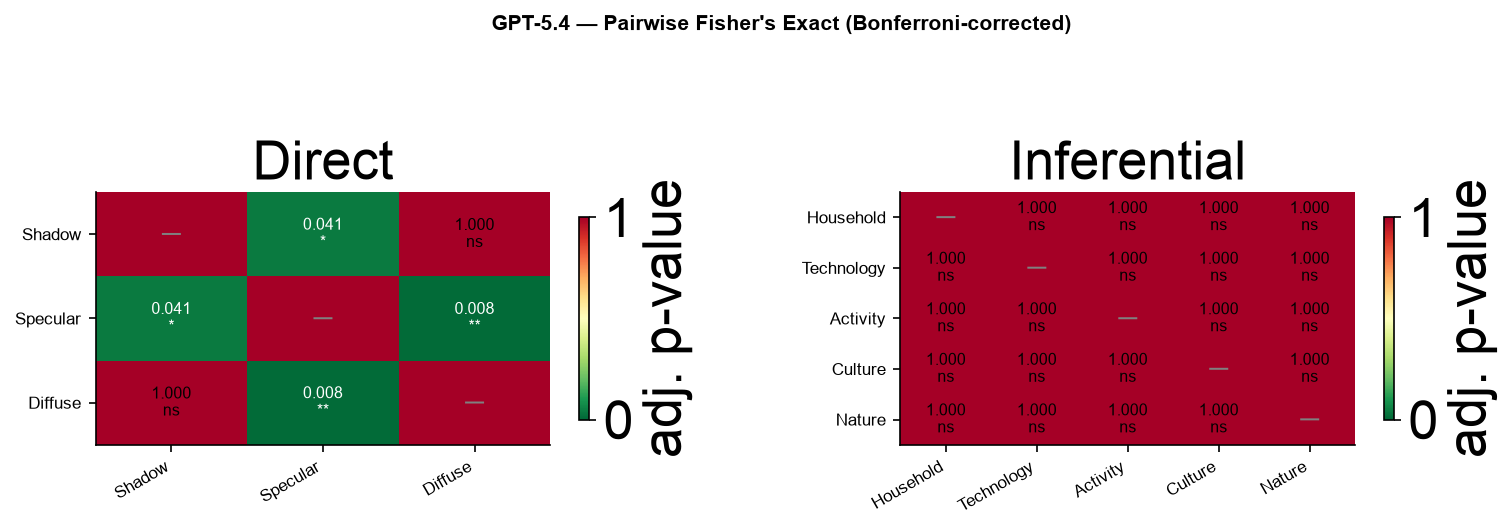

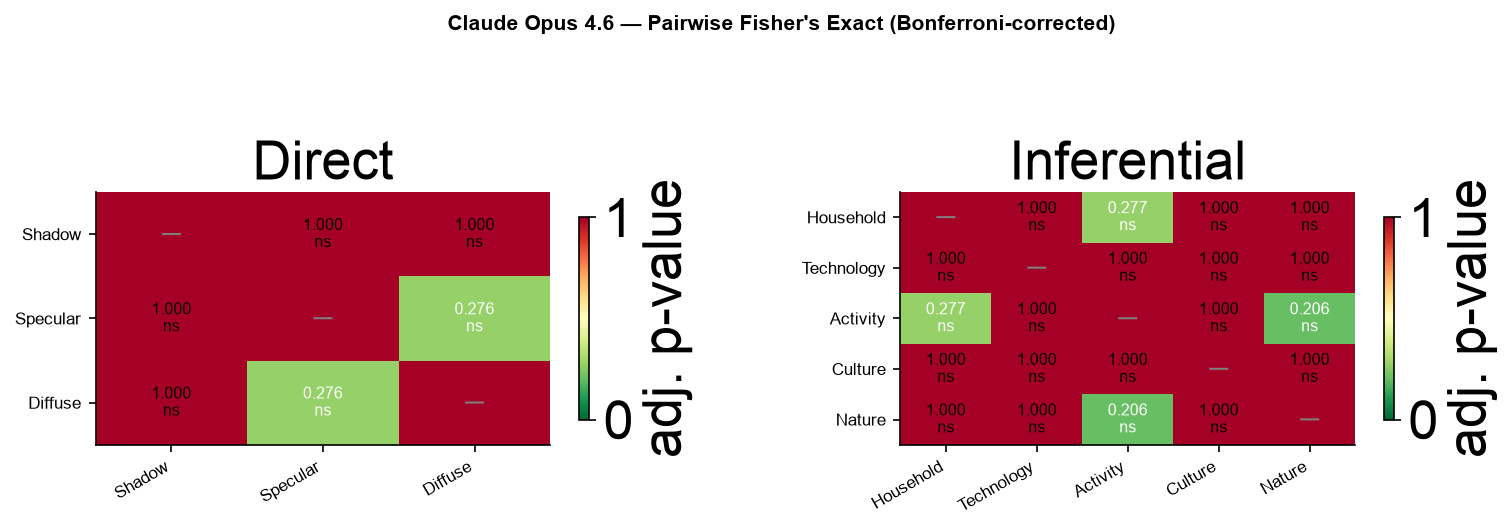

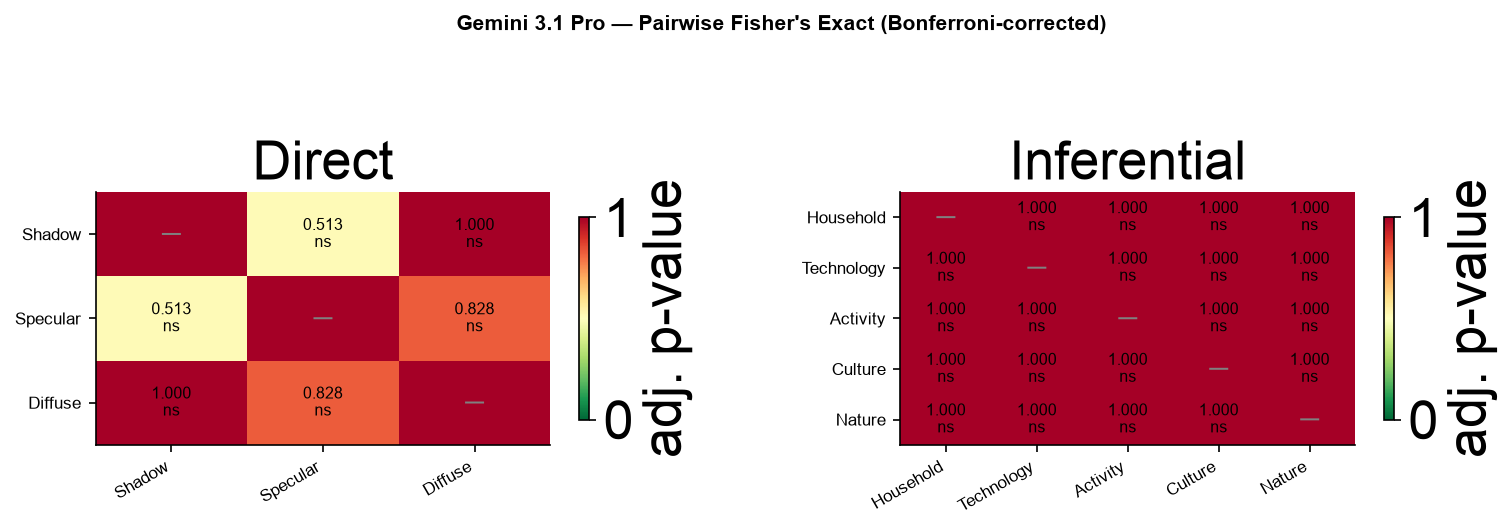

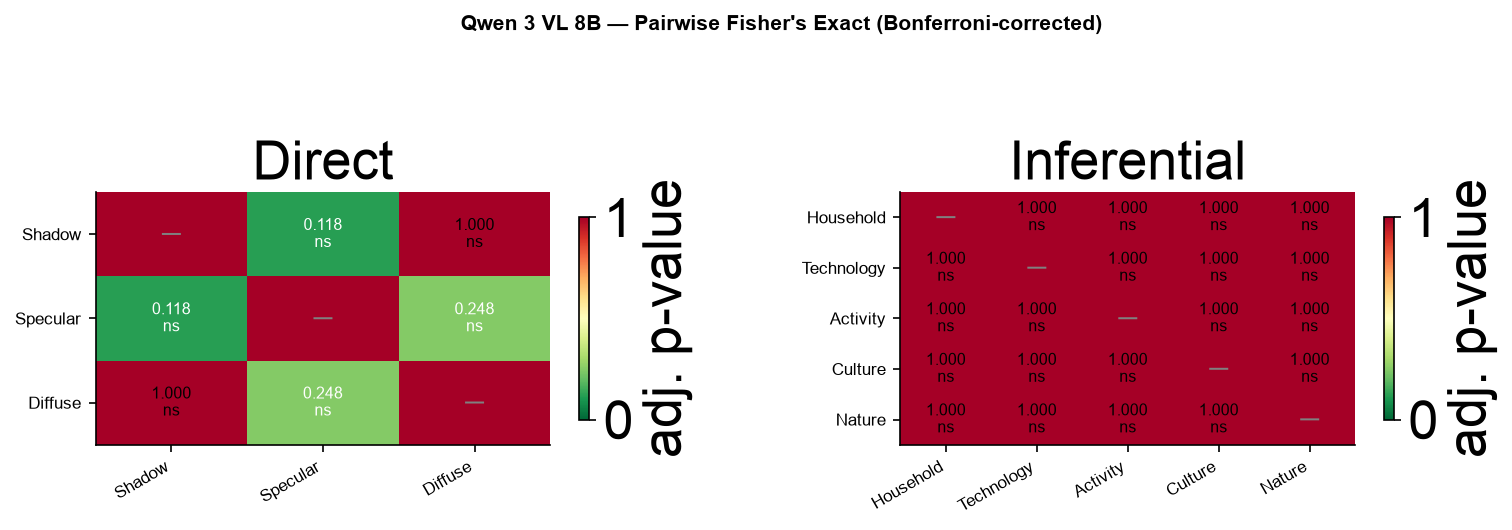

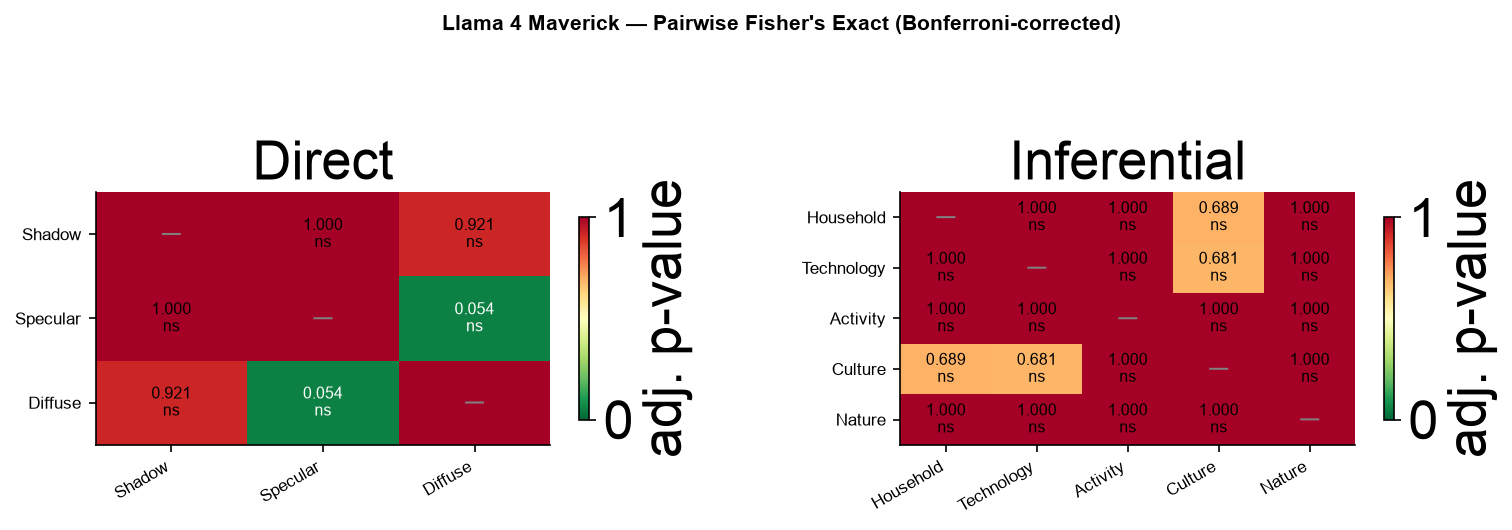

In [7]:
# ── Pairwise p-value heatmaps (one figure per model) ─────────────────────────
for stem in MODEL_STEMS:
    name = DISPLAY_NAMES[stem]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    fig.suptitle(f'{name} — Pairwise Fisher\'s Exact (Bonferroni-corrected)', fontsize=10, fontweight='bold')

    for ax, cats, group_key, title in [
        (axes[0], DIRECT_CATS,      'direct',      'Direct'),
        (axes[1], INFERENTIAL_CATS, 'inferential', 'Inferential'),
    ]:
        pw   = pairwise[stem][group_key]
        n    = len(cats)
        labels = [cat_labels_display[c] for c in cats]

        # Build symmetric matrix
        mat = np.ones((n, n))
        for i, ca in enumerate(cats):
            for j, cb in enumerate(cats):
                if i == j: continue
                key = (ca, cb) if (ca, cb) in pw else (cb, ca)
                if key in pw:
                    mat[i, j] = pw[key]['p_adj']

        im = ax.imshow(mat, vmin=0, vmax=1, cmap='RdYlGn_r', aspect='auto')
        ax.set_xticks(range(n)); ax.set_xticklabels(labels, rotation=30, ha='right', fontsize=8)
        ax.set_yticks(range(n)); ax.set_yticklabels(labels, fontsize=8)
        ax.set_title(title)

        for i in range(n):
            for j in range(n):
                if i == j:
                    ax.text(j, i, '—', ha='center', va='center', fontsize=9, color='gray')
                else:
                    p_val = mat[i, j]
                    txt   = f'{p_val:.3f}\n{stars(p_val)}'
                    color = 'white' if p_val < 0.3 else 'black'
                    ax.text(j, i, txt, ha='center', va='center', fontsize=7.5, color=color)

        plt.colorbar(im, ax=ax, label='adj. p-value', shrink=0.8)

    plt.tight_layout()
    slug = name.lower().replace(' ', '_').replace('.', '')
    save(fig, f'pairwise_fisher_{slug}')
    plt.show()

## Per-model category breakdown

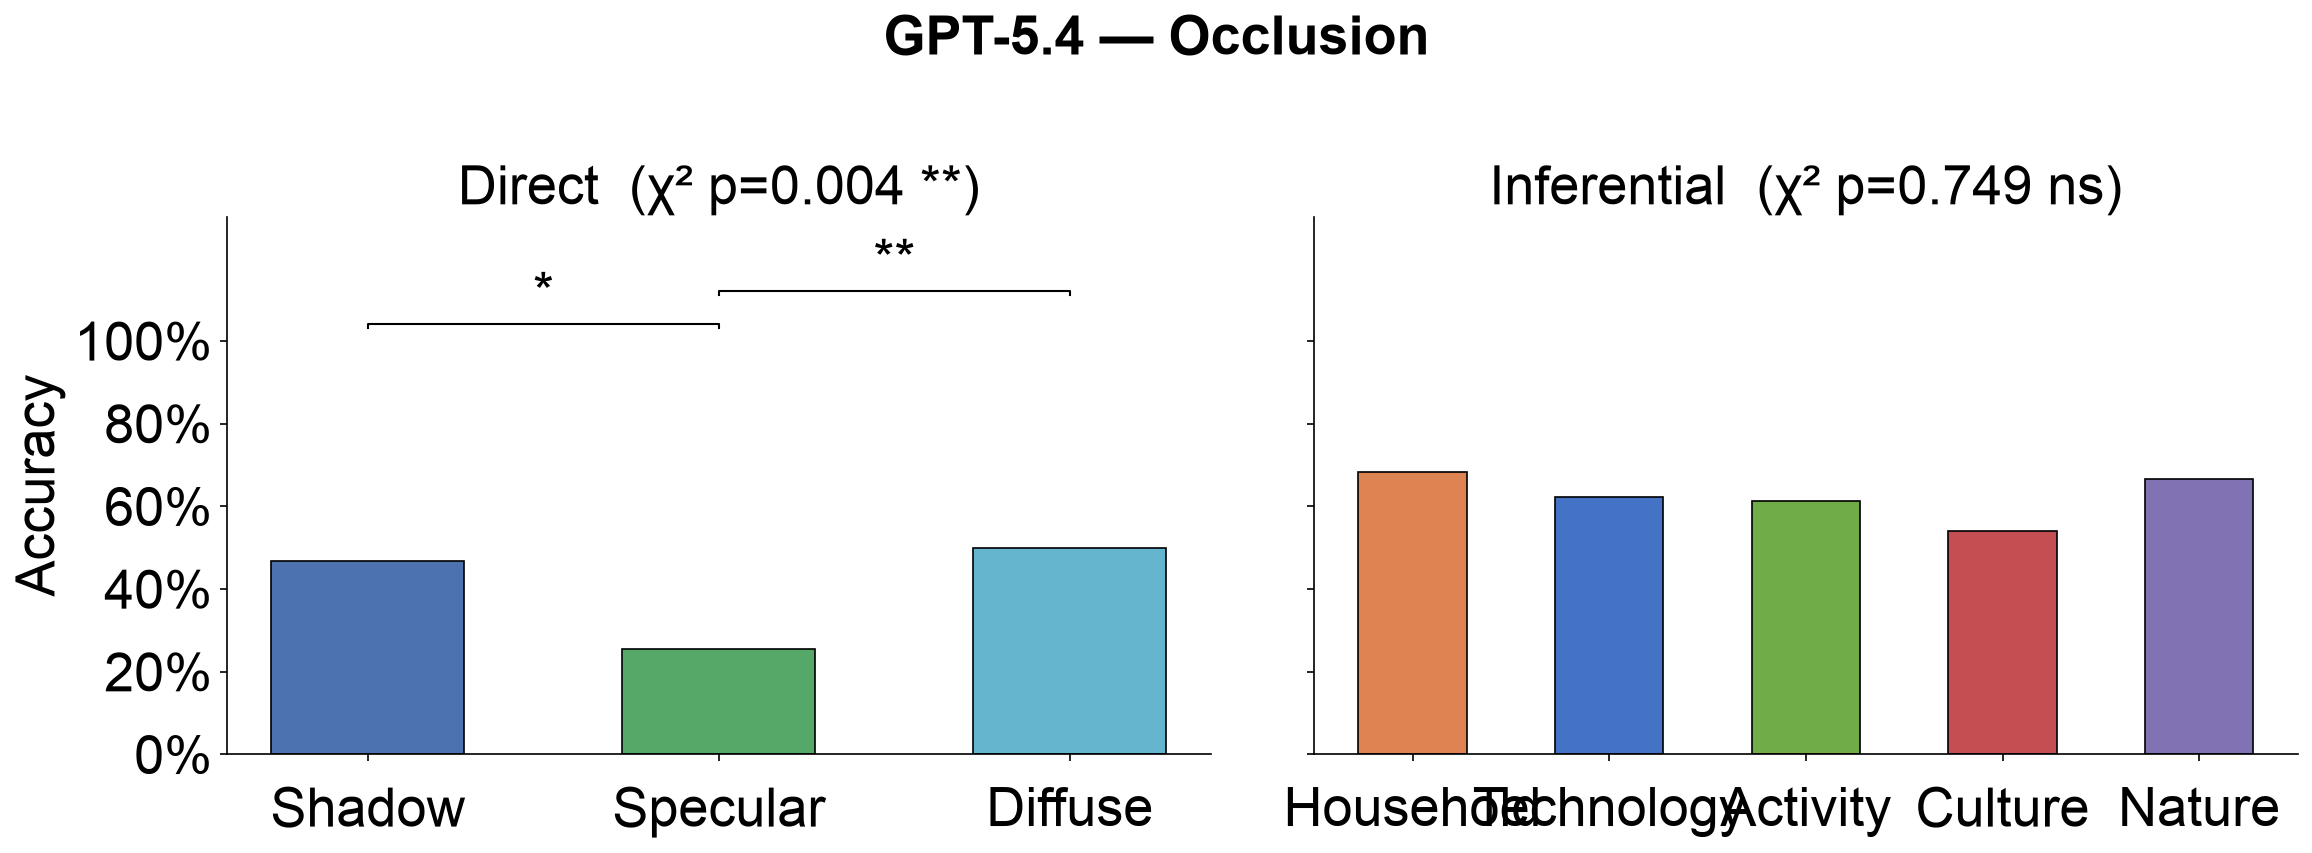

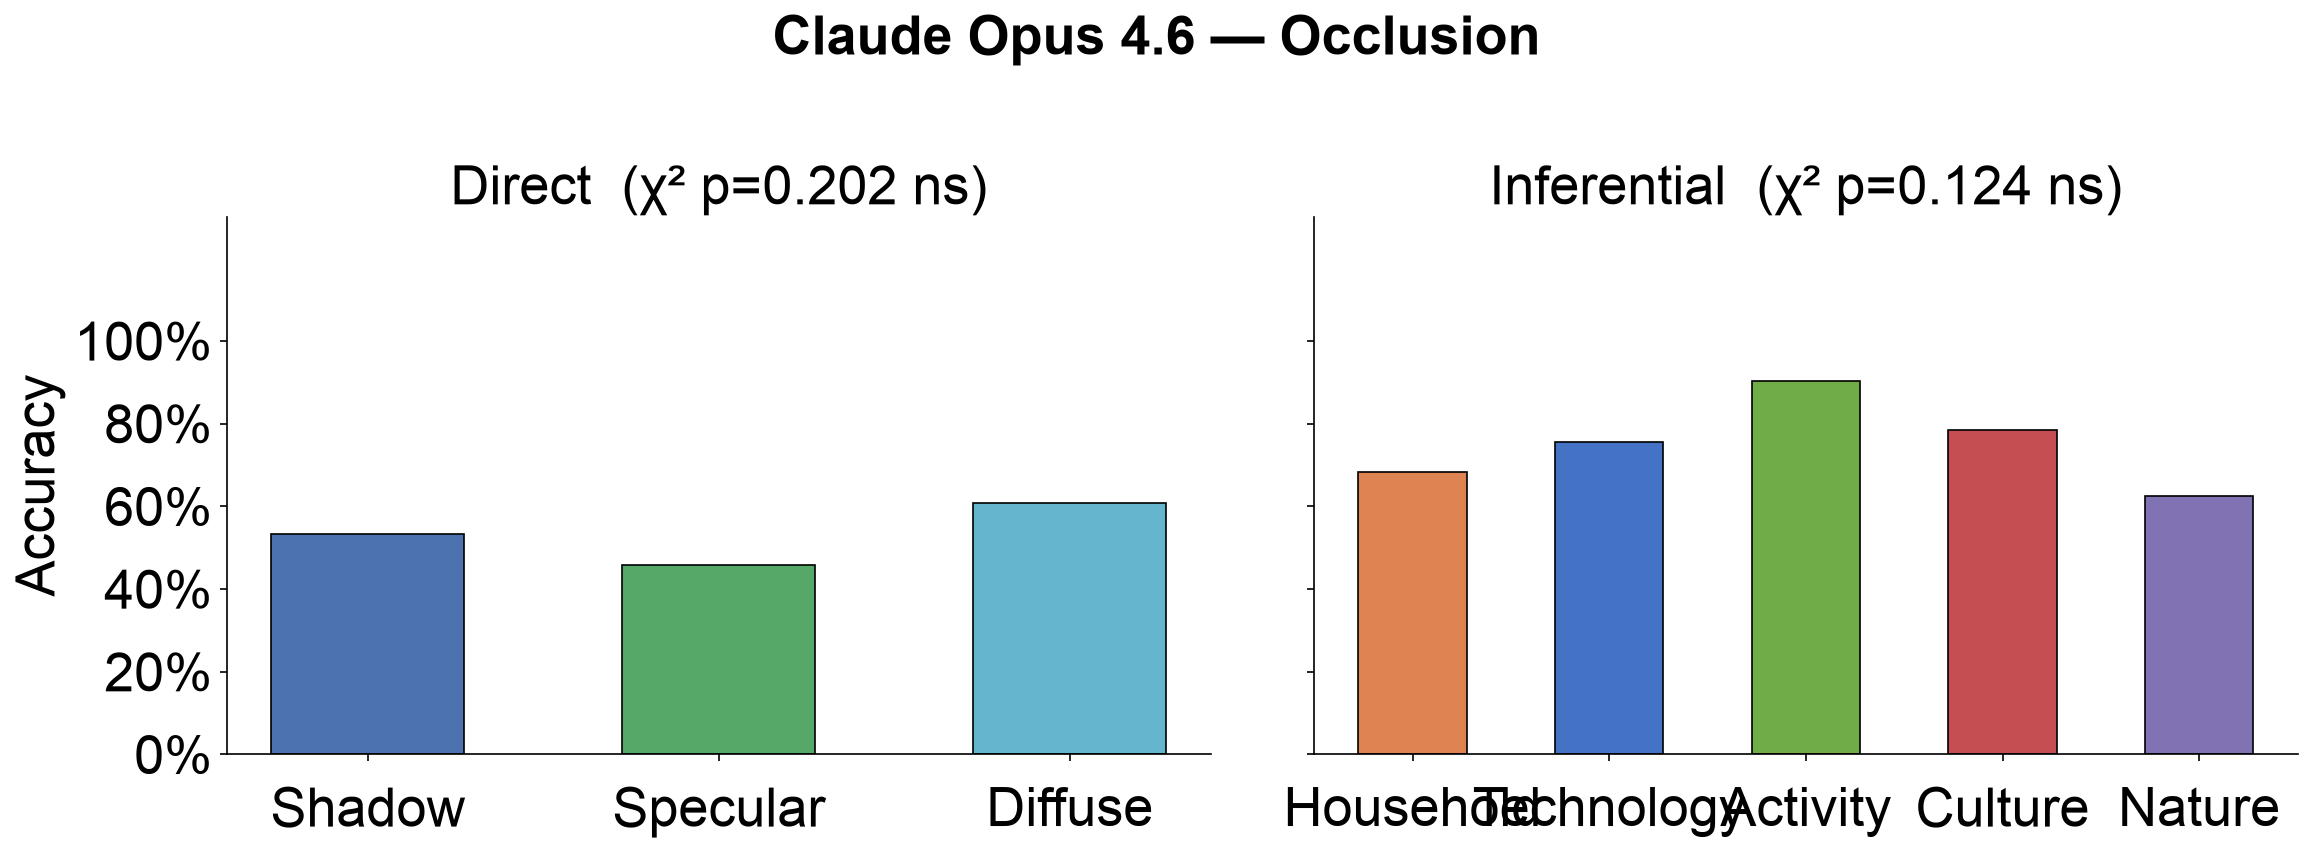

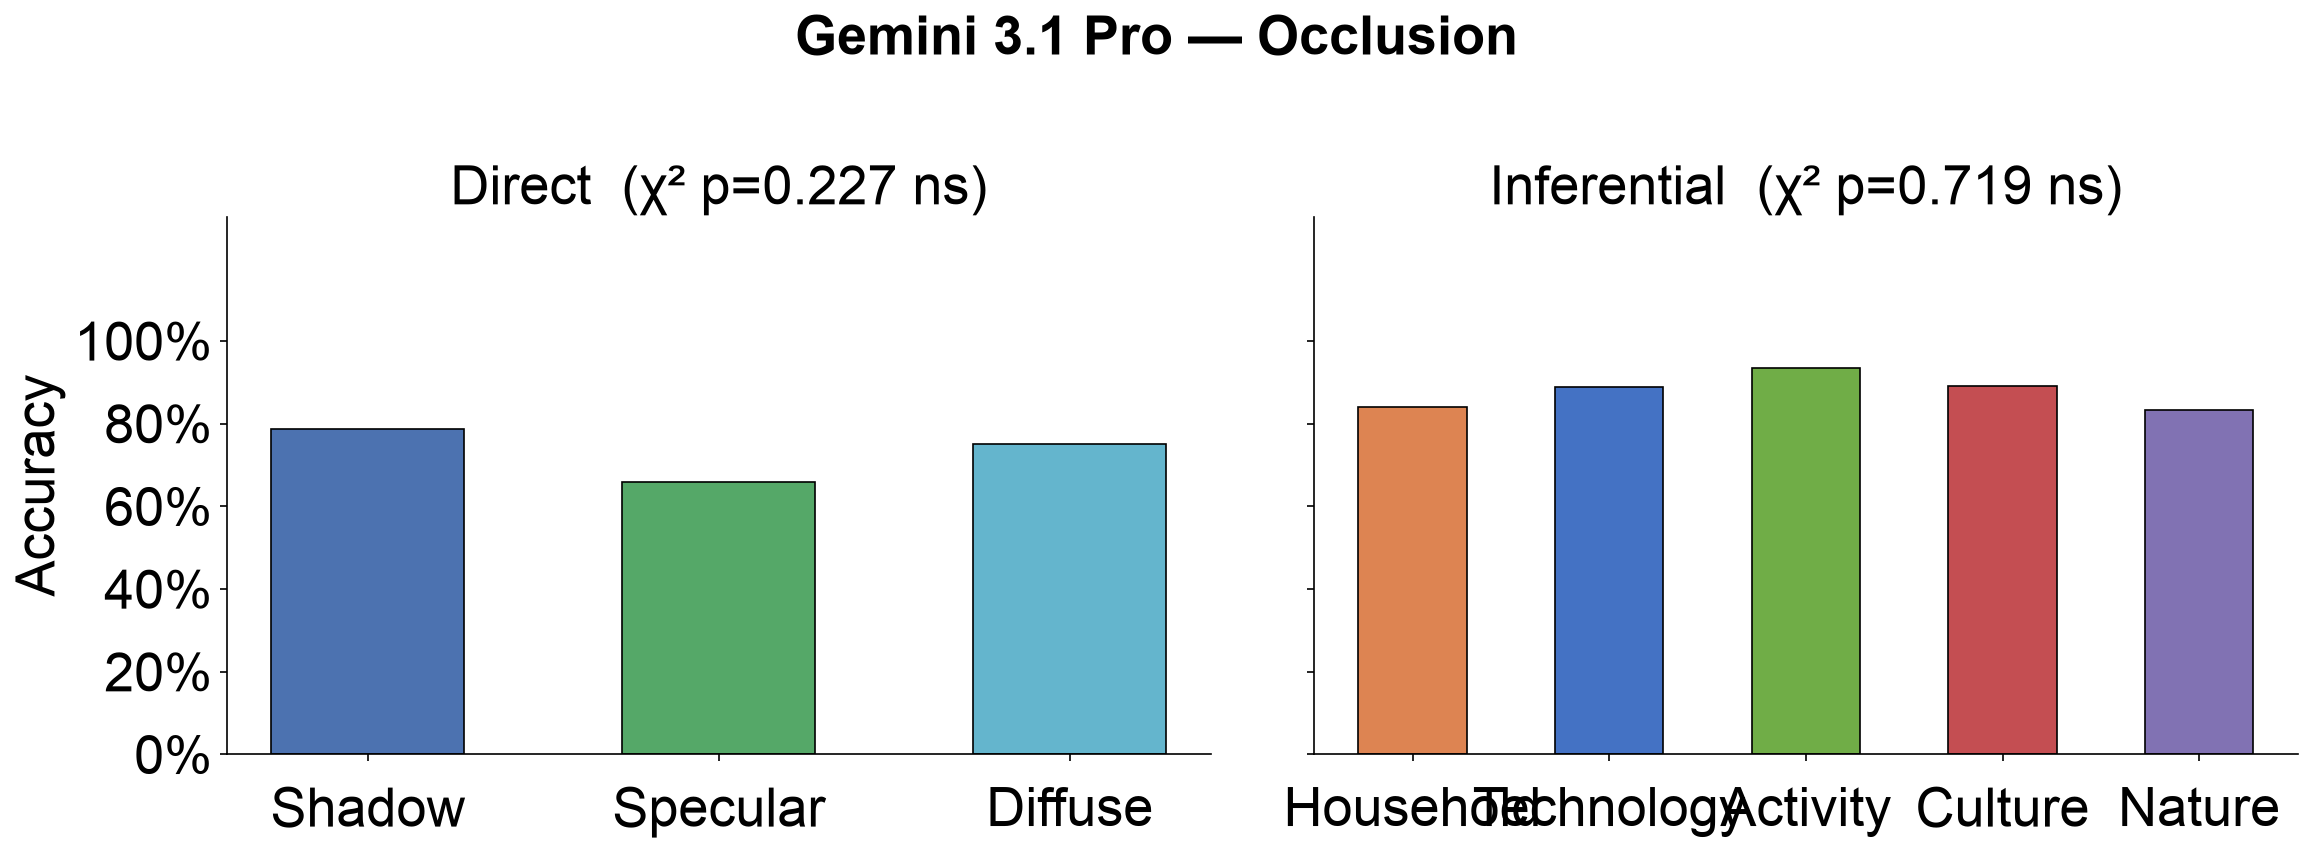

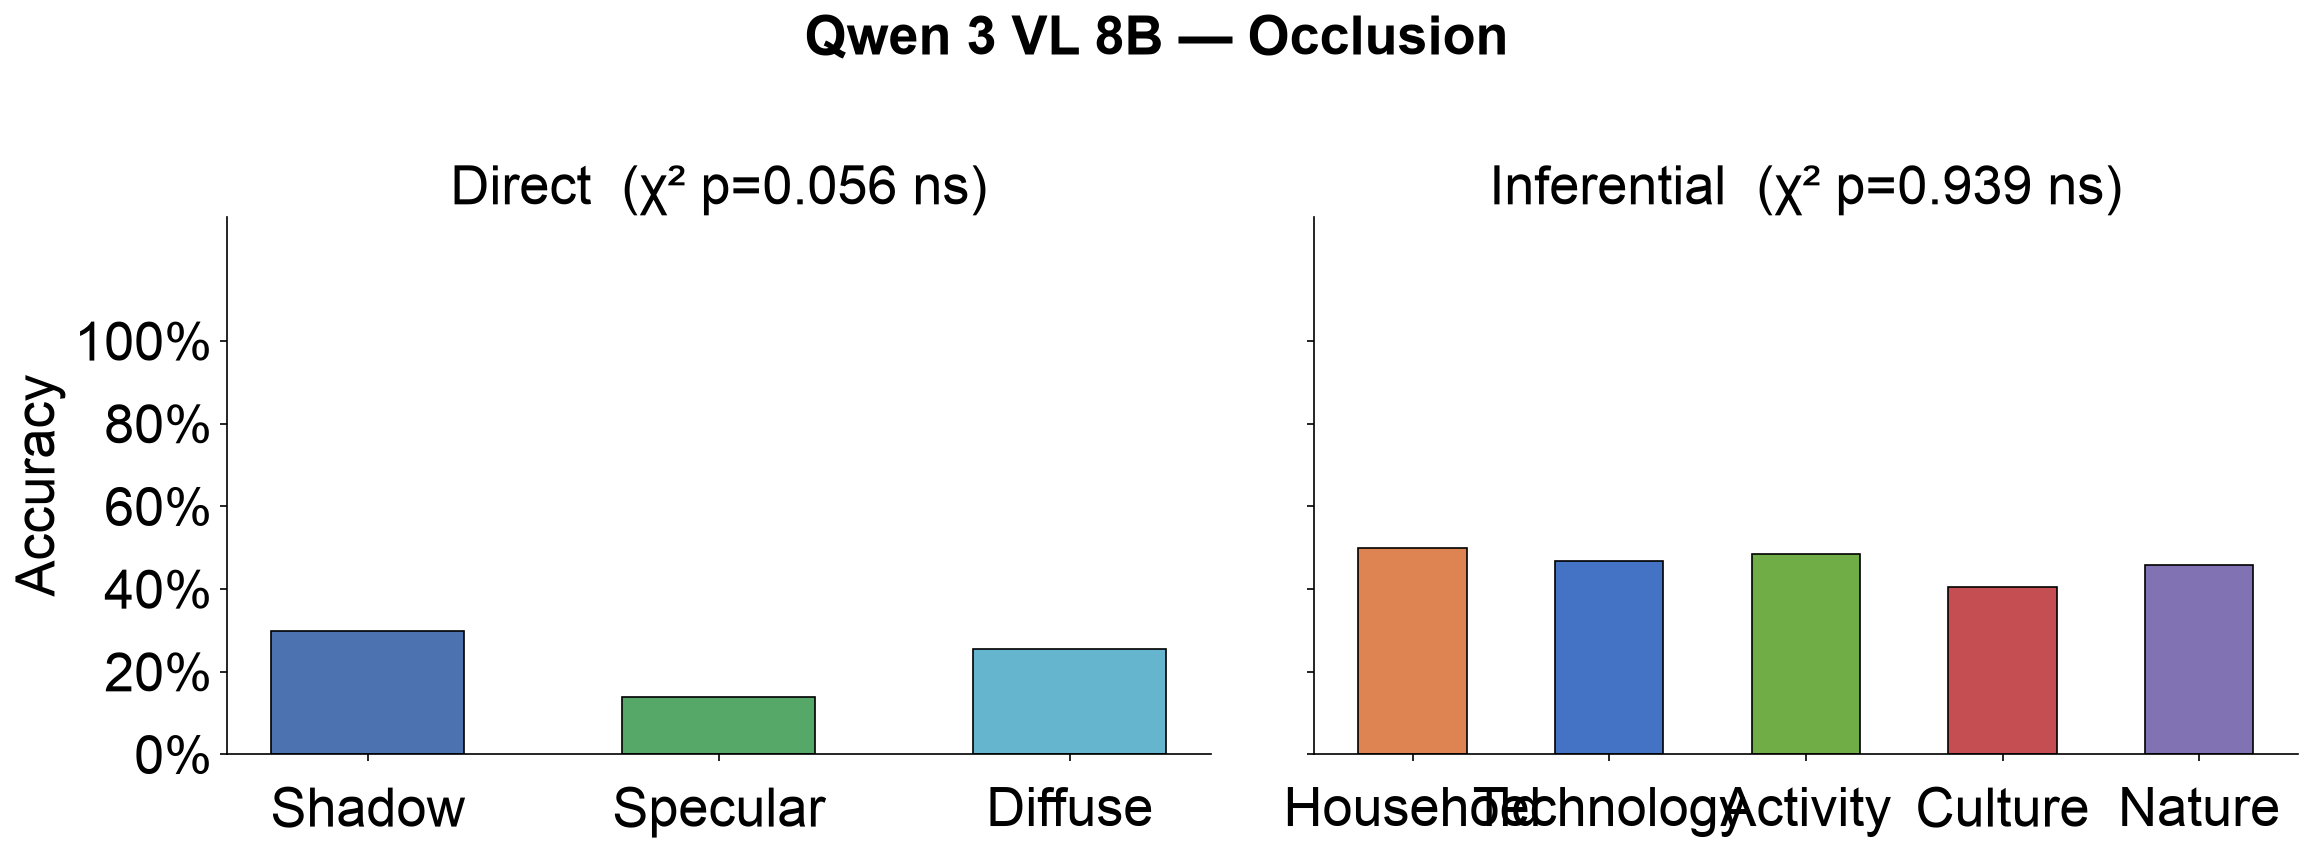

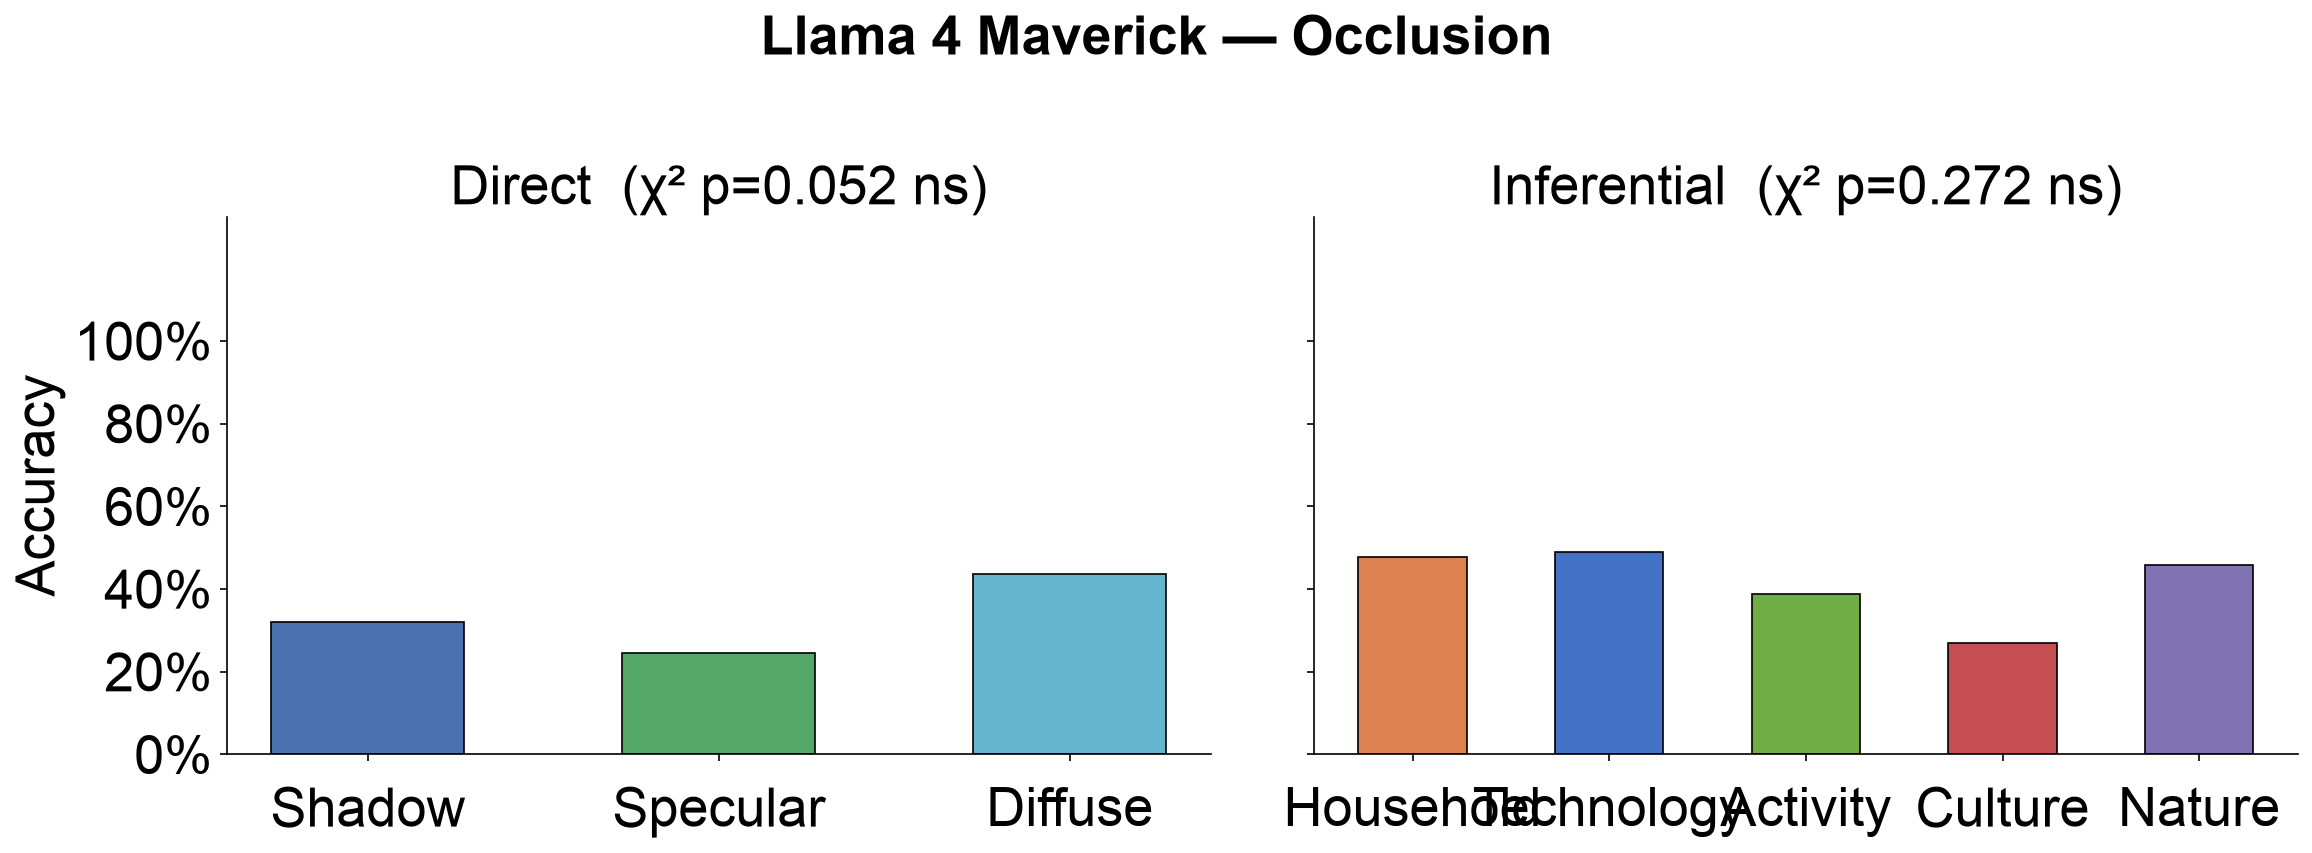

In [8]:
DIRECT_COLORS = {
    'shadow':        '#4C72B0',
    'specular':      '#55A868',
    'water/diffuse': '#64B5CD',
}
INFERENTIAL_COLORS = {
    'household':            '#DD8452',
    'machinery/technology': '#4472C4',
    'sports/activity':      '#70AD47',
    'culture/symbol':       '#C44E52',
    'nature':               '#8172B3',
}
ALL_COLORS = {**DIRECT_COLORS, **INFERENTIAL_COLORS}


def add_sig_brackets(ax, x_positions, accs, pw_results, cats, y_top=105, step=7):
    """Draw significance brackets for all significant pairwise comparisons."""
    sig_pairs = [(ca, cb) for (ca, cb), r in pw_results.items() if r['sig']]
    level = 0
    for ca, cb in sig_pairs:
        if ca not in cats or cb not in cats:
            continue
        xi = cats.index(ca)
        xj = cats.index(cb)
        y  = y_top + level * step
        ax.plot([xi, xi, xj, xj], [y - 1, y, y, y - 1],
                lw=1, color='black', clip_on=False)
        ax.text((xi + xj) / 2, y + 0.5, stars(pw_results[(ca, cb)]['p_adj']),
                ha='center', va='bottom', fontsize=26)
        level += 1


# ── One plot per model ─────────────────────────────────────────────────────────
for stem in MODEL_STEMS:
    name  = DISPLAY_NAMES[stem]
    data  = cat_acc[stem]

    fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
    fig.suptitle(f'{name} — Occlusion', fontsize=26, fontweight='bold')

    for ax, cats, group_key, title in [
        (axes[0], DIRECT_CATS,      'direct',      'Direct'),
        (axes[1], INFERENTIAL_CATS, 'inferential', 'Inferential'),
    ]:
        accs   = [data.get(c, (None, 0))[0] for c in cats]
        ns     = [data.get(c, (None, 0))[1] for c in cats]
        colors = [ALL_COLORS[c] for c in cats]
        labels = [cat_labels_display[c] for c in cats]
        x      = np.arange(len(cats))

        bars = ax.bar(x, accs, color=colors, width=0.55, edgecolor='black', linewidth=0.8)

        pw = pairwise[stem][group_key]
        add_sig_brackets(ax, x, accs, pw, cats, y_top=104, step=8)

        _, p_omni = omnibus[stem][group_key]
        ax.set_title(f'{title}  (χ² p={p_omni:.3f} {stars(p_omni)})', fontsize=26)
        ax.set_xticks(x)
        ax.set_xticklabels(labels, rotation=0, ha='center', fontsize=26)
        ax.tick_params(axis='x', labelsize=26, pad=12)
        ax.tick_params(axis='y', labelsize=26)
        ax.set_ylim(0, 130)
        ax.set_yticks([0, 20, 40, 60, 80, 100])
        ax.yaxis.set_major_formatter(mtick.PercentFormatter())
        if ax is axes[0]:
            ax.set_ylabel('Accuracy', fontsize=26)

    plt.tight_layout()
    slug = name.lower().replace(' ', '_').replace('.', '')
    save(fig, f'cat_accuracy_{slug}')
    plt.show()


## All models — grouped by category

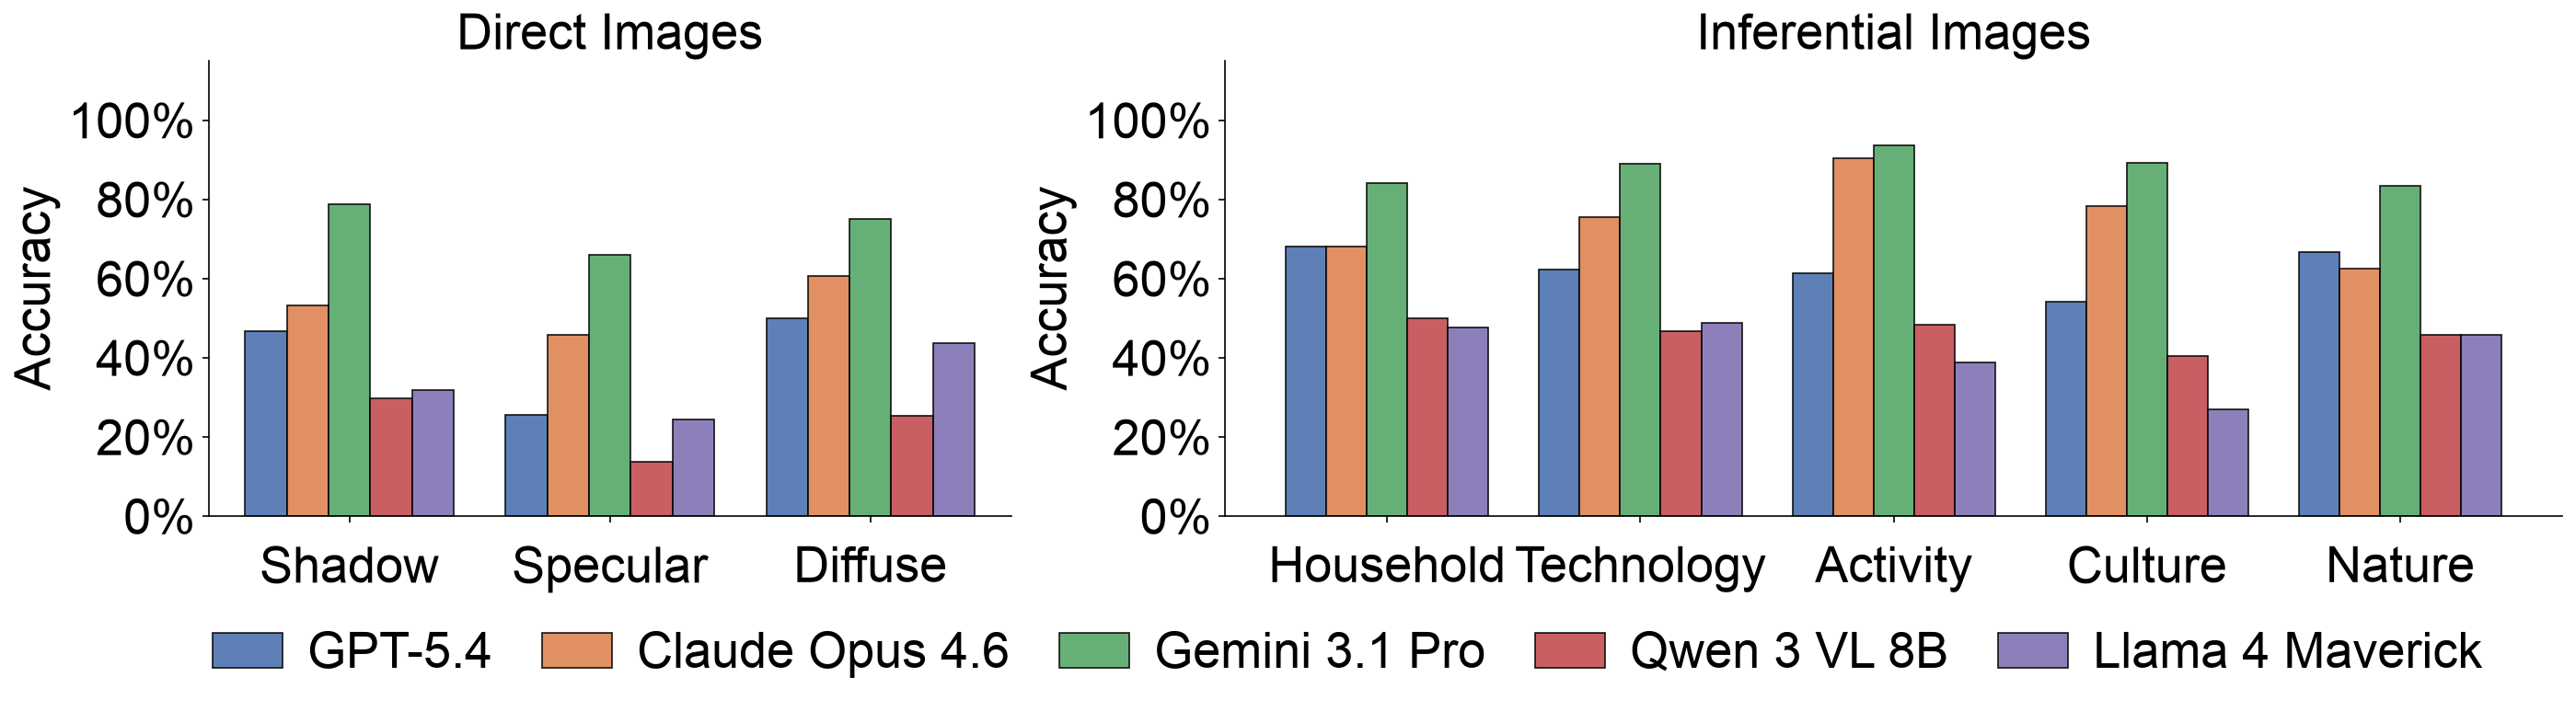

In [9]:
MODEL_COLORS = {
    'gpt-5.4':                                               '#4C72B0',
    'claude-opus-4-6':                                       '#DD8452',
    'gemini-3.1-pro-preview':                                '#55A868',
    'Qwen3-VL-8B-Instruct':                                  '#C44E52',
    'Llama-4-Maverick-17B-128E-Instruct-FP8-9940db5c':       '#8172B3',
}

n_models = len(MODEL_STEMS)
group_w  = 0.8
bar_w    = group_w / n_models
offsets  = np.linspace(-group_w/2 + bar_w/2, group_w/2 - bar_w/2, n_models)

fig, axes = plt.subplots(1, 2, figsize=(22, 5),
                         gridspec_kw={'width_ratios': [3, 5]})

for ax, (cats, side_title) in zip(axes, [(DIRECT_CATS, 'Direct'), (INFERENTIAL_CATS, 'Inferential')]):
    x = np.arange(len(cats))

    for i, stem in enumerate(MODEL_STEMS):
        accs = [cat_acc[stem].get(c, (None, 0))[0] for c in cats]
        ax.bar(x + offsets[i], accs, bar_w,
               label=DISPLAY_NAMES[stem],
               color=MODEL_COLORS[stem], alpha=0.9,
               edgecolor='black', linewidth=0.8)

    ax.set_title(f'{side_title} Images', fontsize=26)
    ax.set_xticks(x)
    ax.set_xticklabels([cat_labels_display[c] for c in cats], rotation=0, ha='center', fontsize=26)
    ax.tick_params(axis='x', labelsize=26, pad=12)
    ax.set_ylim(0, 115)
    ax.set_yticks([0, 20, 40, 60, 80, 100])
    ax.tick_params(axis='y', labelsize=26)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_ylabel('Accuracy', fontsize=26)

# Single shared legend at the bottom
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=n_models,
           bbox_to_anchor=(0.5, -0.08), frameon=False, fontsize=26,
           columnspacing=1.0, handlelength=1.4, handletextpad=0.5)

plt.subplots_adjust(bottom=0.22)
save(fig, 'cat_accuracy_all_models')
plt.show()
